# 01 · Exploratory data analysis

Class balance, lengths, examples, English vs German, and what separates `fusion` from the other classes. Figures are written to `images/`.

## Data download

Needs Kaggle credentials (`~/.kaggle/kaggle.json` or `KAGGLE_API_TOKEN`) and an accepted competition. Skipped when `data/train.csv` already exists.

In [1]:
from hw3.data import download

download()

PosixPath('/home/luka/study/ai_course/ai-text-detection-hw3-ucu-ai/data')

In [2]:
import json
import warnings

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning

from hw3.config import ROOT, art, load_config

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.width", 200, "display.max_columns", 40)
FIG = ROOT / "images"

from hw3 import eda
from hw3.data import load_test, load_train
from hw3.split import neighbors
from hw3.textstats import text_stats

pd.set_option("display.max_colwidth", 240)
train, test = load_train(), load_test()
train.shape, test.shape

/home/luka/study/ai_course/ai-text-detection-hw3-ucu-ai/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


((272352, 7), (25000, 4))

## Class balance by language and domain

In [3]:
eda.class_balance(train)

label                         human      ai  fusion     All
lang  domain                                               
de-DE bundestag               14479   19977   17887   52343
      gutenberg                  31     360      37     428
en-EN arxiv_papers              407   12050    1833   14290
      blog_authorship_corpus  12466   15684   12397   40547
      cnn_news                13395   19488   11402   44285
      euro_court_cases         6277   11141   10160   27578
      gutenberg                 216    6359     341    6916
      house_of_commons         6953   15298    9608   31859
      student_essays          12506   21583   20017   54106
All                           66730  121940   83682  272352

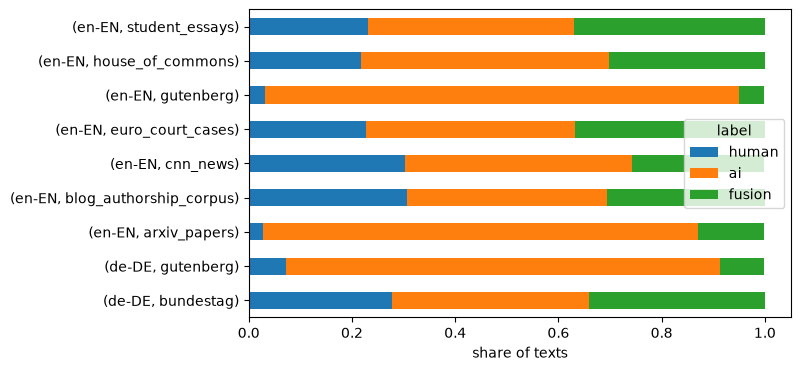

In [4]:
ax = eda.plot_class_balance(train)
ax.figure.savefig(FIG / "eda_class_balance.png", dpi=150, bbox_inches="tight")

Domain mix of train vs test (test labels are unknown, only the domain column is compared).

In [5]:
pd.DataFrame(
    {
        "train": train.groupby(["lang", "domain"]).size() / len(train),
        "test": test.groupby(["lang", "domain"]).size() / len(test),
    }
).round(3)

train   test
lang  domain                              
de-DE bundestag               0.192  0.143
      gutenberg               0.002  0.004
en-EN arxiv_papers            0.052  0.067
      blog_authorship_corpus  0.149  0.178
      cnn_news                0.163  0.197
      euro_court_cases        0.101  0.064
      gutenberg               0.025  0.070
      house_of_commons        0.117  0.118
      student_essays          0.199  0.159

## Text lengths

In [6]:
eda.length_table(train)

count    10%    50%     90%     max
lang  label                                         
de-DE ai       20337.0  136.0  430.0   648.0  2679.0
      fusion   17924.0  357.0  584.0   910.0  2952.0
      human    14510.0  160.0  584.0   925.0  2963.0
en-EN ai      101603.0  123.0  481.0   908.0  2996.0
      fusion   65758.0  116.0  389.0  1298.0  3000.0
      human    52220.0   98.0  439.0  1189.1  2998.0

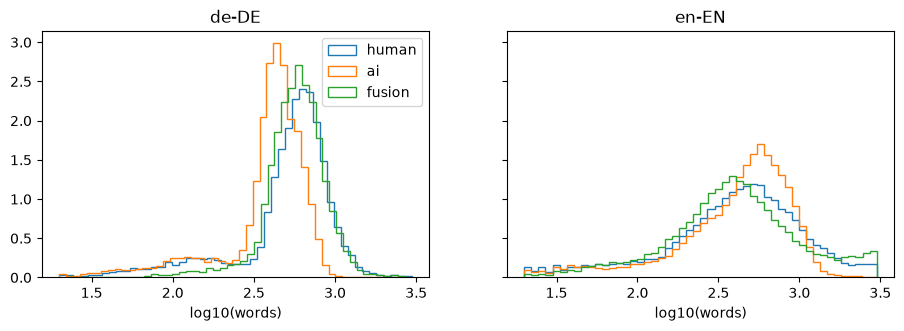

In [7]:
fig = eda.plot_lengths(train)
fig.savefig(FIG / "eda_lengths.png", dpi=150, bbox_inches="tight")

## Examples

Two random texts per language and class (fixed seed), whitespace-collapsed and cut to 220 characters.

In [8]:
eda.examples(train, per_group=2)

,lang,domain,label,snippet
0,de-DE,bundestag,ai,"Es ist ein schwerer Tag für unsere Republik, wenn wir uns in diesen Räumlichkeiten wiederfinden, um über das Budget zu diskutieren. Ein Budget, das angeblich die Grundlage für ein florierendes Deutschland schaffen soll – …"
1,de-DE,bundestag,ai,"Honorable Kollegen, liebe Kolleginnen, wir stehen heute hier und diskutieren die Auswirkungen der Pandemie auf unsere Hochschulen und Studierenden. Es ist unbestritten, dass das Jahr der Pandemie immense Herausforderunge …"
2,de-DE,bundestag,fusion,"Herr Präsident! Sehr geehrte Damen und Herren! Werte Kolleginnen und Kollegen! Werter Herr Minister Heil, ich kannte Johann Wolfgang von Goethe bislang nur als großen deutschen Dichter und wusste nicht, dass er auch Visi …"
3,de-DE,bundestag,fusion,"Sehr geehrter Herr Präsident, ich danke für die Promotion ehrenhalber, muss sie aber zurückweisen. Das ist gefährlich in der Politik. Ich habe keinen Doktortitel erworben. Ich habe nicht promoviert, habe das auch nicht v …"
4,de-DE,bundestag,human,Frau Präsidentin! Verehrte Kolleginnen und Kollegen! Seit nunmehr zehn Jahren sind einige wenige Bundeswehrangehörige im Südsudan im Rahmen von UNMISS stationiert. Die politische Lage in dem Land ist allerdings weiterhin …
5,de-DE,bundestag,human,"Herr Präsident, vielen Dank. – Meine sehr verehrten Damen und Herren! Wenn wir über den Libanon reden, geht es Ihnen wahrscheinlich ähnlich wie mir: Man erinnert sich an die Bilder von Bürgerkrieg, von Attentaten, von Mi …"
6,en-EN,student_essays,ai,"Let's face it, school isn't always the most exciting thing in the world. Sometimes it feels like just another drag on our already busy schedules. But sports? Now that's something that gets me pumped! Being able to run, j …"
7,en-EN,student_essays,ai,"To the esteemed members of the , I am writing to express my fervent support for extending the current school day by one and a half hours. While I understand this proposal may seem unconventional at first glance, I firmly …"
8,en-EN,cnn_news,fusion,He hasn't had the easiest year defending his economic record and actions on immigration. And a playful appearance on The Colbert Report brought no light relief for President Obama. Amid jokes about his approval ratings a …
9,en-EN,cnn_news,fusion,"'I cannot explain, justify or defend the horrifying deaths of hundreds of Palestinians': Ed Miliband has come out against Israel's ground attack on Gaza . Ed Miliband has said he opposes Israeli military action in Gaza, …"


## English vs German

Stylometric medians per language and class on a balanced sample of 2000 texts per cell.

In [9]:
sample = train.groupby(["lang", "label"]).sample(2000, random_state=0)
eda.stats_by_class(sample, text_stats(sample.text))

lang                  de-DE                         en-EN                    
label                    ai    fusion     human        ai    fusion     human
n_words             425.000   586.500   592.000   476.000   394.000   440.500
n_chars            3081.500  4111.000  4120.000  3117.500  2335.500  2529.500
word_len              6.247     6.004     5.902     5.467     4.943     4.757
sent_len_mean        16.706    15.756    15.439    18.683    18.000    18.305
sent_len_std          6.886     9.175     9.917     7.942     9.869    10.643
ttr_200               0.745     0.735     0.740     0.730     0.675     0.650
upper_ratio           0.045     0.045     0.046     0.019     0.021     0.026
digit_ratio           0.000     0.002     0.002     0.000     0.003     0.004
punct_per_word        0.101     0.105     0.110     0.106     0.077     0.082
newlines_per_100w     0.000     0.000     0.000     0.000     0.000     0.000

Subword cost per language for the two model families used later (encoder windows and LM token budget).

In [10]:
eda.token_fertility(train, ["FacebookAI/xlm-roberta-base", "Qwen/Qwen2.5-0.5B"])

,model,lang,tokens_per_word,tokens_p50,tokens_p95,share_over_510,windows_p95,windows_p99
0,FacebookAI/xlm-roberta-base,de-DE,1.504,784.0,1452.00,0.839,3.0,4.0
1,FacebookAI/xlm-roberta-base,en-EN,1.411,618.0,2042.15,0.599,5.0,8.0
2,Qwen/Qwen2.5-0.5B,de-DE,1.849,967.0,1775.00,0.879,4.0,5.0
3,Qwen/Qwen2.5-0.5B,en-EN,1.230,541.5,1825.60,0.534,4.0,7.0


Words most over-represented in `ai` and `fusion` relative to `human` (log-odds z-score, balanced samples).

In [11]:
pd.concat(
    {f"{lang}: {label} vs human": eda.distinctive_words(train, lang, label) for lang in ["en-EN", "de-DE"] for label in ["ai", "fusion"]},
    axis=1,
)

en-EN: ai vs human               en-EN: fusion vs human               de-DE: ai vs human               de-DE: fusion vs human              
           more in ai more in human         more in fusion more in human         more in ai more in human         more in fusion more in human
0                 our           had                    our          said             unsere           das                 müssen          dank
1                this     applicant            furthermore           you                die           ich      herausforderungen           ich
2               these            he                  these           she                uns         haben                sondern           das
3              within           was              potential          have            unserer          noch                 unsere        vielen
4                  we           the               learning           was                 zu          auch                    nur    herzlichen
5           potential         court                crucial            do            sondern           man           gesellschaft          noch
6               legal          said                   this         after            zukunft           bei                    die           sie
7         significant            on              essential          will  herausforderungen          aber                unserer           man
8                 let          have          understanding            so             lassen          dann          sicherstellen           bei
9               their            be            significant            he       gesellschaft            im               lösungen         haben
10             future          will            individuals          year          gemeinsam         jetzt                    wir          dann
11              often          been                   must           get             müssen            ja                     zu         jetzt
12           learning       because             challenges            up               zeit            da                    uns         schon
13      understanding          that               approach           cnn                nur         schon                fördern            da
14            through         would               moreover          last      verantwortung          wenn           gleichzeitig         danke

## What makes `fusion` different

Nearest-neighbour cosine similarity (rare-word TF-IDF inside each language × domain block, same computation as the split in `02_split`).

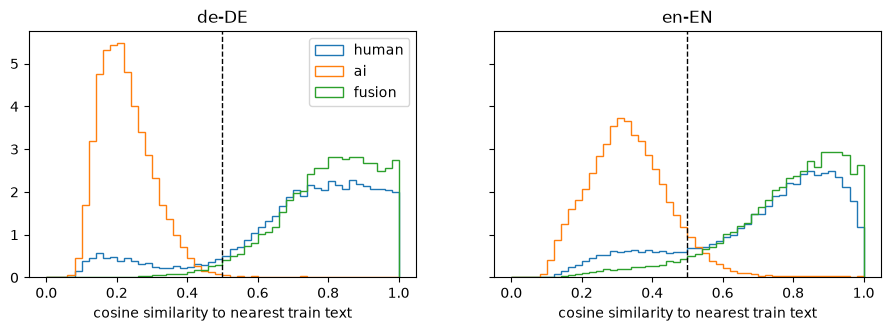

In [13]:
split_cfg = load_config("split")
top = eda.top_neighbor(train, neighbors(split_cfg))
fig = eda.plot_neighbor_similarity(top, split_cfg["link_threshold"])
fig.savefig(FIG / "eda_neighbor_similarity.png", dpi=150, bbox_inches="tight")

In [14]:
linked = top.neighbor_label.where(top.sim >= split_cfg["link_threshold"], "no near-duplicate")
pd.crosstab([top.lang, top.label], linked, normalize="index").round(3)

neighbor_label     ai  fusion  human  no near-duplicate
lang  label                                            
de-DE ai        0.005   0.000  0.002              0.994
      fusion    0.000   0.477  0.491              0.032
      human     0.002   0.853  0.001              0.144
en-EN ai        0.065   0.003  0.014              0.918
      fusion    0.000   0.417  0.507              0.077
      human     0.018   0.762  0.032              0.188

Where inside a fusion text the human source survives: share of the fusion text's word 3-grams found in its matched human text, by relative position.

lang                  de-DE     en-EN
length_ratio count  598.000  2402.000
             mean     0.954     0.832
             std      0.097     0.183
             min      0.426     0.180
             10%      0.836     0.572
             50%      0.981     0.859
             90%      1.024     1.026
             max      1.528     2.533
kept         count  598.000  2402.000
             mean     0.745     0.789
             std      0.151     0.135
             min      0.327     0.284
             10%      0.543     0.599
             50%      0.745     0.815
             90%      0.953     0.951
             max      0.999     1.000

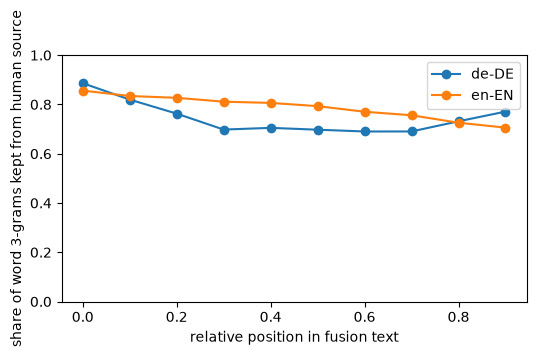

In [15]:
profile = eda.fusion_profile(train, top, split_cfg["link_threshold"])
fig = eda.plot_fusion_profile(profile)
fig.savefig(FIG / "eda_fusion_profile.png", dpi=150, bbox_inches="tight")
profile.groupby("lang")[["length_ratio", "kept"]].describe(percentiles=[0.1, 0.5, 0.9]).round(3).T

## Findings used in the modelling

| finding (cells above) | where it is used |
|---|---|
| German has only `bundestag` and `gutenberg`; class priors differ strongly by domain (gutenberg EN 92% ai, arXiv 84% ai); the test domain mix differs from train (gutenberg 7.4% of test vs 2.7% of train) | `two_stage.yaml` (domain routing), `ensemble.yaml` (domain as stacker feature), `class_weight: balanced` everywhere |
| fusion texts have a near-duplicate human source (97% DE, 92% EN), AI texts almost never do | `split.yaml` (grouping) |
| fusion rewrites are uneven inside a text: German keeps the most source text at the start and the least in the middle (U-shape), English loses source text steadily towards the end | segment-level spread in `lm_features.yaml`, per-window min/max/std in `encoder.yaml` |
| length and stylometry move in different directions per language: ai is the shortest class in German but fusion is in English; ai uses more punctuation per word than human in English but less in German; type-token ratio separates the classes in English only | `ensemble.yaml` (`stack_by: lang`, `text_stats: true`) |
| length tails: German fusion texts are almost never short (10th percentile 357 words vs 160 human, 136 ai); in English, texts over about 1,000 words are rarely ai (90th percentile 908 ai vs 1,189 human, 1,298 fusion) | `n_words` in the X4 stacker (gradient boosting can use non-monotone length effects; TF-IDF normalisation discards length) |
| ai texts contain numbers less often (median digit ratio 0 vs 0.002–0.004 for human and fusion) | `digit_ratio` in the X4 stacker |
| German needs more subword tokens per word (1.50 vs 1.41 for XLM-R, 1.85 vs 1.23 for Qwen) and most texts exceed 510 tokens | `encoder.yaml` (`max_chunks` per language), `lm_features.yaml` (`max_tokens` per language) |

Hypothesis, not shown by an output above: German capitalises nouns and forms compounds, so cased words and char n-grams may help there. The uppercase share itself is equal across German classes (0.045 / 0.045 / 0.046). It is tested as an option in the German grid of `lang_tuned.yaml` (X1), not assumed.